# Optimización de Inventario


$$
    x_{t+1} = x_t + p_t - \xi_{t+1}
$$

In [239]:
import numpy as np
import matplotlib.pyplot as plt


def demanda():
    y = np.random.exponential(scale=3) + np.random.randint(10, 20)
    return int(y)


def system(x, a):
    e = demanda()
    y = np.max([x+a-e,0])
    h = np.array([x,a,e])
    return y, h

def reward(hv, pv=6, pp = 5, ps=1):
    x = hv[0]
    a = hv[1]
    e = hv[2]
    product_cost = a * pp * ps
    product_sold = np.min([e, x + a]) * pv
    penal = np.max([e-(x + a), 0])
    y = product_sold - product_cost - penal
    return y

# Construyendo nuestra red Neuronal

Notemos que ahora $\mathbf{x}=(x,a,\xi)\in\mathbb{R}^2$

In [247]:
NEURONS = 3

def sigmoid(x):
    return (1 + np.exp(-x)) ** -1

from neuralnetworks.nn import descent_gradent, verif_model


NEURONS = 5
x_0 = np.array([1,1,1])
W = np.random.normal(size=(NEURONS, 3))
B = 2 * np.ones(NEURONS)
v = np.matmul(W, x_0) + B
C = list(range(NEURONS))
Sv = sigmoid(v)

WQ = W.flatten()

print(WQ.reshape((NEURONS, 3)))

Q = np.zeros((NEURONS, NEURONS))
Q[0,:] = C
Q[1: 4 , :] = W.T
Q[4, :] = B



Q0 = Q.flatten()
def Nmodel(Q, x, act = sigmoid, neurons = NEURONS):
    C = Q[:NEURONS]
    W = Q[NEURONS: 4 * NEURONS]
    B = Q[4*NEURONS:]
    W = W.reshape((3, NEURONS)).T
    v = np.matmul(W, x) + B
    Sv = sigmoid(v)
    CSv = C * Sv
    return CSv.sum()



x_0 = 100
h0 = np.array([x_0, 0, 0])
c_0 = reward(np.array([x_0, 0, 0]))
c_0

x_1, h1 = system(x_0, Nmodel(Q0, h0))
x_1, h1

[[-1.50216744 -1.52172788  1.36929468]
 [-0.52544837  0.11892544 -0.94752278]
 [ 0.29475229  0.00552702  0.86781193]
 [-0.01330794  0.94525944  0.56255598]
 [-0.84583336  0.01825461 -1.77132146]]


(np.float64(82.9839761742752),
 array([100.        ,   3.98397617,  21.        ]))

In [268]:
def train_data(x_0, days):
    history = []
    S = 40
    for _ in range(days):
        a = 0 if x_0 >= S else S/2
        x_0, hd = system(x_0, a)
        history.append(hd)
    return history

train = train_data(100, 20)


def gain(data):
    c = 0
    for d in data:
        c+= reward(d)
    return c


def system(x, a):
    e = demanda()
    y = np.max([x+a-e,0])
    h = np.array([x,a,e])
    return y, h


def Nerror(func, pars, days=100, x_0=100):
    history = []
    ic = np.array([x_0, 0, 0])
    for m in range(days):
        # print(ic)
        x, h = system(x_0, Nmodel(pars, ic))
        x_0 = x
        ic = h
        history.append(h)
    ell = - gain(history)
    return ell


def Nlearn(theta):
    return Nerror(Nmodel, theta)

pars_0 = descent_gradent(Nlearn, Q0, 0.01, stop=100)
pars_0





/tmp/ipykernel_69692/1438239748.py:4: RuntimeWarning: overflow encountered in exp
  return (1 + np.exp(-x)) ** -1


KeyboardInterrupt: 

In [264]:
days = 200

ic = np.array([x_0, 0, 0])
history = [ic]
for m in range(days):
    x, h = system(x_0, Nmodel(pars_0, ic))
    ic = h
    history.append(h)

history

[array([100,   0,   0]),
 array([100.        ,   3.98397617,  22.        ]),
 array([100.        ,   4.99999985,  20.        ]),
 array([100.        ,   4.99999982,  17.        ]),
 array([100.        ,   4.99999904,  20.        ]),
 array([100.        ,   4.99999982,  12.        ]),
 array([100.        ,   4.99998407,  23.        ]),
 array([100.        ,   4.99999997,  18.        ]),
 array([100.        ,   4.99999946,  35.        ]),
 array([100.,   5.,  17.]),
 array([100.        ,   4.99999904,  11.        ]),
 array([100.        ,   4.99997205,  17.        ]),
 array([100.        ,   4.99999904,  22.        ]),
 array([100.        ,   4.99999994,  19.        ]),
 array([100.        ,   4.99999969,  19.        ]),
 array([100.        ,   4.99999969,  11.        ]),
 array([100.        ,   4.99997205,  17.        ]),
 array([100.        ,   4.99999904,  15.        ]),
 array([100.        ,   4.99999705,  19.        ]),
 array([100.        ,   4.99999969,  22.        ]),
 array([100

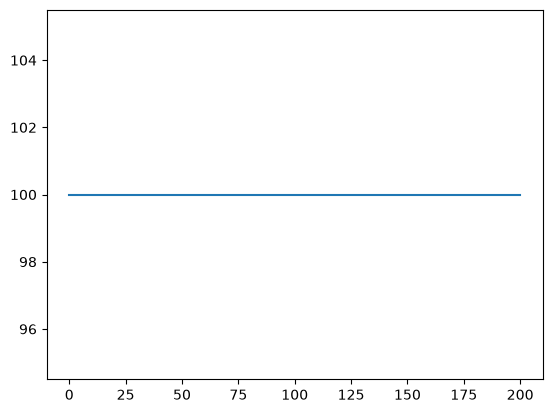

In [265]:
tray = [h[0] for h in history]

plt.plot(tray)